<a href="https://colab.research.google.com/github/antoniomezasabalza-ui/Decodificador_0A15_Hexadecimal/blob/main/CNN_Clasificacion_OV3660.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ==========================================
# CELDA 1: IMPORTAR BIBLIOTECAS
# ==========================================

import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from google.colab import files

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

print("Bibliotecas cargadas correctamente.")


TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Bibliotecas cargadas correctamente.


In [2]:

# ==========================================
# CELDA 2: SUBIR DATASET
# ==========================================

uploaded = files.upload()

nombre_zip = next(iter(uploaded.keys()))

print("Archivo recibido:", nombre_zip)

# Extraer el archivo ZIP
carpeta_destino = "/content"

with zipfile.ZipFile(nombre_zip, 'r') as zip_ref:
    zip_ref.extractall(carpeta_destino)

print("Dataset descomprimido correctamente.")


Saving Dataset_OV3660_dividido.zip to Dataset_OV3660_dividido.zip
Archivo recibido: Dataset_OV3660_dividido.zip
Dataset descomprimido correctamente.


In [3]:

# ==========================================
# CELDA 3: VERIFICAR DATASET
# ==========================================

RUTA_DATASET = "/content/Dataset_OV3660_dividido"

clases = [
    "bola_unicel",
    "cubo_plastico",
    "sin_objeto"
]

subconjuntos = [
    "train",
    "validation",
    "test"
]

for conjunto in subconjuntos:

    print("\n", conjunto.upper())

    for clase in clases:

        ruta = Path(RUTA_DATASET) / conjunto / clase

        imagenes = list(ruta.glob("*.jpg"))
        imagenes += list(ruta.glob("*.jpeg"))

        print(f"{clase}: {len(imagenes)} imágenes")

print("\nVerificación terminada.")



 TRAIN
bola_unicel: 140 imágenes
cubo_plastico: 140 imágenes
sin_objeto: 140 imágenes

 VALIDATION
bola_unicel: 30 imágenes
cubo_plastico: 30 imágenes
sin_objeto: 30 imágenes

 TEST
bola_unicel: 30 imágenes
cubo_plastico: 30 imágenes
sin_objeto: 30 imágenes

Verificación terminada.


In [4]:

# ==========================================
# CELDA 4: PARAMETROS DEL DATASET
# ==========================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

CLASES = [
    "bola_unicel",
    "cubo_plastico",
    "sin_objeto"
]

print("Tamaño de entrada:", IMG_SIZE)
print("Canales: RGB (3)")
print("Batch size:", BATCH_SIZE)
print("Clases:", CLASES)


Tamaño de entrada: (128, 128)
Canales: RGB (3)
Batch size: 16
Clases: ['bola_unicel', 'cubo_plastico', 'sin_objeto']


In [5]:

# ==========================================
# CELDA 5: CARGAR IMAGENES
# ==========================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASES,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET + "/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASES,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    RUTA_DATASET + "/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    class_names=CLASES,
    shuffle=False
)

print("Conjuntos de datos cargados correctamente.")


Found 420 files belonging to 3 classes.
Found 90 files belonging to 3 classes.
Found 90 files belonging to 3 classes.
Conjuntos de datos cargados correctamente.


In [6]:

# ==========================================
# CELDA 6: VERIFICAR DIMENSIONES
# ==========================================

for imagenes, etiquetas in train_ds.take(1):

    print("Dimensiones de las imágenes:", imagenes.shape)
    print("Dimensiones de las etiquetas:", etiquetas.shape)

    print("Mínimo de píxeles:", tf.reduce_min(imagenes).numpy())
    print("Máximo de píxeles:", tf.reduce_max(imagenes).numpy())


Dimensiones de las imágenes: (16, 128, 128, 3)
Dimensiones de las etiquetas: (16, 3)
Mínimo de píxeles: 0.0
Máximo de píxeles: 255.0


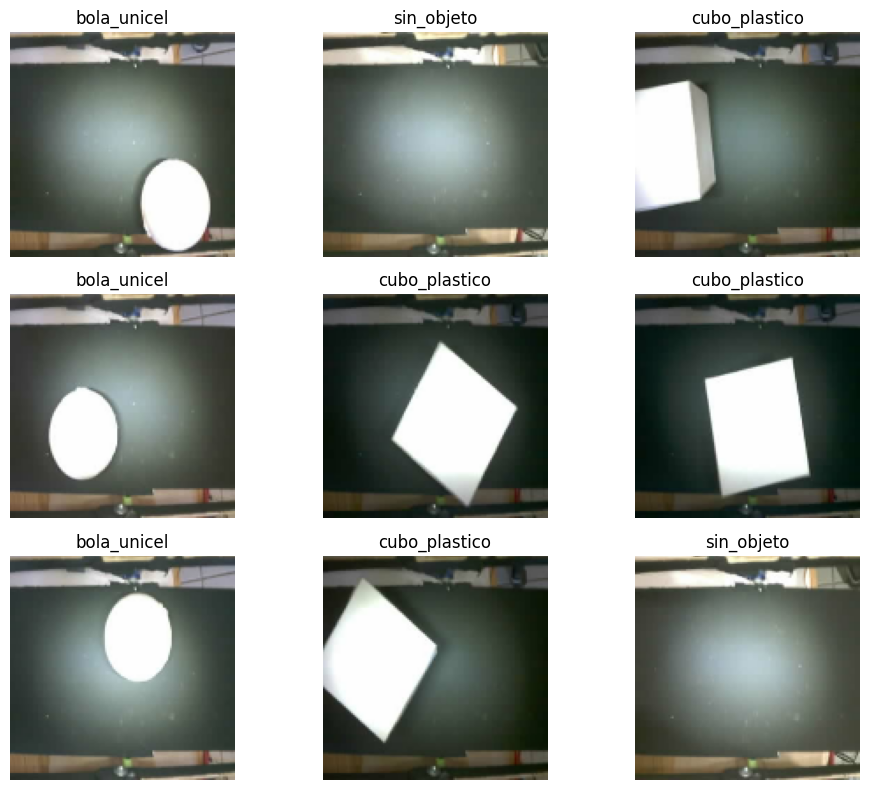

In [7]:

# ==========================================
# CELDA 7: VISUALIZAR IMAGENES
# ==========================================

plt.figure(figsize=(10, 8))

for imagenes, etiquetas in train_ds.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            imagenes[i].numpy().astype("uint8")
        )

        indice = np.argmax(etiquetas[i].numpy())

        plt.title(CLASES[indice])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:

# ==========================================
# CELDA 8: CONSTRUIR CNN
# ==========================================

modelo = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(128, 128, 3)
    ),

    # Normalizar píxeles de 0-255 a 0-1
    tf.keras.layers.Rescaling(1./255),

    # Primer bloque convolucional
    tf.keras.layers.Conv2D(
        16,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Segundo bloque convolucional
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Tercer bloque convolucional
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    # Clasificador
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        3,
        activation="softmax"
    )

])

modelo.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

# ==========================================
# CELDA 9: COMPILAR MODELO
# ==========================================

modelo.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)

print("Modelo compilado correctamente.")


Modelo compilado correctamente.


In [10]:

# ==========================================
# CELDA 10: CONFIGURAR ENTRENAMIENTO
# ==========================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

guardar_mejor = tf.keras.callbacks.ModelCheckpoint(
    "/content/mejor_modelo.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Callbacks configurados.")


Callbacks configurados.


In [11]:

# ==========================================
# CELDA 11: ENTRENAR CNN
# ==========================================

historial = modelo.fit(

    train_ds,

    validation_data=val_ds,

    epochs=40,

    callbacks=[
        early_stop,
        guardar_mejor
    ]

)

print("Entrenamiento terminado.")


Epoch 1/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 20s 390ms/step - accuracy: 0.3976 - loss: 1.0981 - val_accuracy: 0.4778 - val_loss: 1.0836
Epoch 2/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5000 - loss: 1.0490 - val_accuracy: 0.5667 - val_loss: 0.9818
Epoch 3/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.6286 - loss: 0.8529 - val_accuracy: 0.5889 - val_loss: 0.7494
Epoch 4/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6548 - loss: 0.6200 - val_accuracy: 0.6444 - val_loss: 0.5619
Epoch 5/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6548 - loss: 0.5717 - val_accuracy: 0.6222 - val_loss: 0.6512
Epoch 6/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7119 - loss: 0.5316 - val_accuracy: 0.7556 - val_loss: 0.5094
Epoch 7/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7881 - loss: 0.4806 - val_accuracy: 0.7111 - val_loss: 0.4898
Epoch 8/40
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8286 - loss: 0.4561 - val_accuracy: 0.6222 -